# Report 05: the main line of the paper

This notebook walks through the figures of [`report/report.pdf`](report/report.pdf)
in the order of the paper. It does not reimplement anything: every cell calls
the existing `images/make_*.py` scripts, which also write the `images/fig_*.pdf`
files used by `report/report.tex`. The numbers quoted in the text are printed
by the same calls.

**Before running.** Run from the repository root. The long computations are
cached in `tmp/` (not in git); the scripts read those caches and only recompute
when they are missing:

| Needed for | Cache | Produced by |
| --- | --- | --- |
| Sec. 3.2, 4.2, App. A (`f(E)`, threshold) | `tmp/regular_fraction_cache/` | `python regular_fraction_scan.py` (hours; `--t-mult=2` for App. A) |
| Sec. 4.3 (saddle sample) | `tmp/inspect_cache/` | computed on first run (~2 min) |
| Sec. 4.4 (section at E ≈ 52) | `tmp/lyapunov_section_cache/`, `tmp/lyapunov_orbit_cache/` | `python lyapunov_poincare_section.py`, `python lyapunov_section_periodic_orbits.py` |

The periodic orbits of Appendix B are read from the stored outputs of
`report04.ipynb`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
assert (ROOT / "system.py").exists(), "run this notebook from the repository root"
for p in (ROOT, ROOT / "images"):
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))

# Every figure script saves through make_orbit_figures.save, which writes the
# PDF and closes the figure. Wrap it so the figure is also shown here. This
# must happen before the other make_* modules import `save`.
import make_orbit_figures as orbit_figs

_save_pdf = orbit_figs.save

def save_and_show(fig, name):
    display(fig)
    _save_pdf(fig, name)

orbit_figs.save = save_and_show

import make_potential_figure as potential_fig
import make_threshold_figure as threshold_fig
import make_section_figures as section_figs
import make_fraction_figure as fraction_fig
import make_saddle_sample_figure as saddle_fig
import make_lyapunov_section_figures as lyap_figs

## 2. The model

Centre-symmetric motions reduce the system to particle 1 moving in
$V_\mathrm{sym}$. The script prints the four wells ($E_\mathrm{eq}\approx1.98765$)
and four saddles ($E_s\approx1.99689$) with their Hessian eigenvalues.

Figure `fig_potential.pdf`.

well   q1 = (3.6644771591, 3.6644771591)   E_eq = 1.9876519036   Hessian eig = [0.02280546 0.24543988]
saddle q1 = (3.1926014724, 5.0)        E_s  = 1.9968870664   Hessian eig = [-0.02068536  0.30497151]
barrier E_s - E_eq = 0.009235


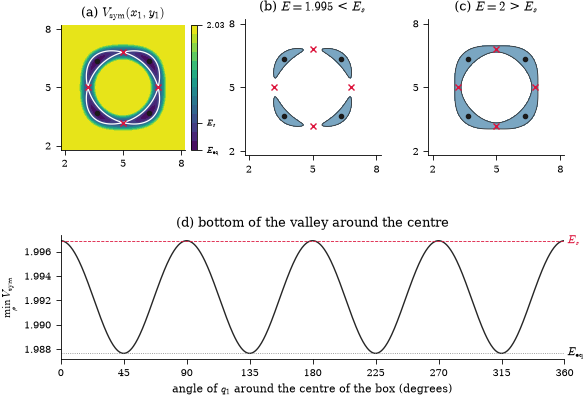

wrote images\fig_potential.pdf


In [2]:
potential_fig.main()

## 3.2 Regular or chaotic: the threshold on $\lambda_T$

Histograms of $u=\lambda_T T/\ln T$; a trajectory is regular if $u<3.2$.
Statistics over all energies are printed first.

Figure `fig_threshold.pdf` (needs `tmp/regular_fraction_cache/`).

   E     n   reg: median  p99 | chaotic: p1 | frac 2<u<5 | f(c=2,3.2,5)
  1.990 3600   0.50  0.75 |    nan | 0.000 | 1.000 1.000 1.000
  1.995 3600   0.58  1.80 |    5.0 | 0.078 | 0.899 0.939 0.976
  1.996 3600   0.59  1.72 |    5.0 | 0.094 | 0.638 0.667 0.733
  1.997 3600   0.58  1.63 |    5.5 | 0.033 | 0.434 0.448 0.467
  1.998 3600   0.59  1.50 |    6.3 | 0.024 | 0.343 0.354 0.367
  1.999 3600   0.60  1.76 |    6.9 | 0.016 | 0.304 0.315 0.319
  2.000 3600   0.60  1.26 |    8.3 | 0.006 | 0.295 0.298 0.301
  2.005 3600   0.63  1.58 |   13.6 | 0.010 | 0.191 0.199 0.201
  2.010 3600   0.66  1.83 |   11.3 | 0.025 | 0.191 0.207 0.216
  2.020 3600   0.72  1.44 |    9.5 | 0.007 | 0.136 0.141 0.144
  2.050 3600   0.70  0.95 |   28.1 | 0.000 | 0.036 0.036 0.036
  2.100 3600   0.82  1.28 |   12.8 | 0.001 | 0.117 0.117 0.117
  2.200 3600   0.78  1.73 |   10.9 | 0.004 | 0.231 0.233 0.235
  2.400 3600   0.77  0.96 |   16.1 | 0.001 | 0.222 0.223 0.223
  2.700 3600   0.78  1.76 |   11.6 | 0.008 | 0

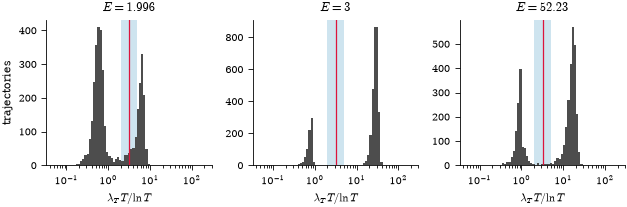

wrote images\fig_threshold.pdf


In [3]:
threshold_fig.main()

## 4.1 Regular and chaotic trajectories

Case 2 at four energies: trajectory and Poincaré section.

Figure `fig_energy_sections.pdf`.

v = 0.05: E = 2.007344, max dE/E = 1.5e-08


v = 0.1527: E = 2.028170, max dE/E = 2.6e-08


v = 0.9821: E = 2.969432, max dE/E = 1.0e-06


v = 3: E = 11.004844, max dE/E = 6.7e-08


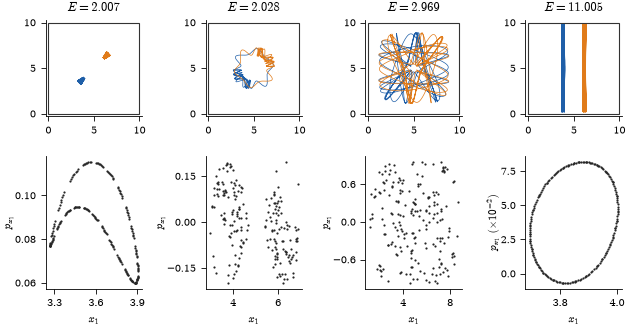

wrote images\fig_energy_sections.pdf


In [4]:
section_figs.energy_figure()

## 4.2 The regular fraction $f(E)$ — main result

The printed table also gives $f$ for every other integration time in the
cache: this is the convergence table of Appendix A.

Figure `fig_regular_fraction.pdf` (needs `tmp/regular_fraction_cache/`).

   E      T_std  f(T_std) | other T: f, reg->chaotic, chaotic->reg
  1.990   10000  1.000   | T=2500: 1.000, 0, 0 | T=5000: 1.000, 0, 0 | T=20000: 1.000, 0, 0
  1.995   10000  0.939   | T=2500: 1.000, 0, 221 | T=5000: 0.985, 0, 166 | T=20000: 0.895, 158, 1
  1.996   10000  0.667   | T=2500: 0.996, 0, 1182 | T=20000: 0.630, 134, 0
  1.997   10000  0.448   | T=2500: 0.631, 0, 660 | T=20000: 0.428, 73, 0
  1.998   10000  0.354   | T=2500: 0.463, 0, 395 | T=20000: 0.339, 51, 0
  1.999   10000  0.315   | T=2500: 0.396, 0, 290 | T=20000: 0.301, 52, 0
  2.000   10000  0.298   | T=2500: 0.361, 0, 225 | T=20000: 0.292, 20, 0
  2.005   10000  0.199   | T=2500: 0.226, 0, 97 | T=20000: 0.189, 37, 0
  2.010   10000  0.207   | T=2500: 0.246, 0, 139 | T=20000: 0.188, 71, 0
  2.020   10000  0.141   | T=2500: 0.188, 0, 171 | T=20000: 0.134, 24, 0
  2.050   10000  0.036   | T=2500: 0.043, 0, 25 | T=20000: 0.036, 1, 0
  2.100    2494  0.117   | T=4987: 0.116, 4, 0
  2.200    2436  0.233   | T=4872: 0.229

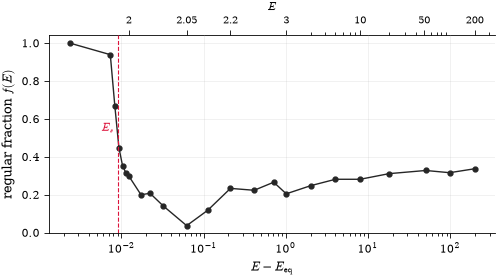

wrote images\fig_regular_fraction.pdf


In [5]:
fraction_fig.main()

## 4.3 Low energy: why $f$ drops near the saddles

Nine random trajectories at $E=1.996$, just below $E_s$, folded into one well,
with their finite-time Lyapunov exponents.

Figure `fig_saddle_sample.pdf`.

cache hit: tmp\inspect_cache\E1.996_T10000_seed1.npz
picked candidates: #21: u=7.3, #16: u=0.3, #7: u=0.9, #1: u=3.3, #3: u=0.5, #28: u=0.4, #15: u=6.1, #11: u=4.8, #25: u=0.6
all 30 candidates: 0.63 regular


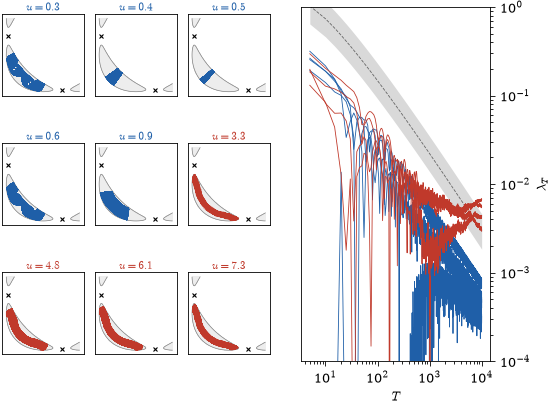

wrote images\fig_saddle_sample.pdf


In [6]:
saddle_fig.main()

## 4.4 High energy: where the regular motion is

Poincaré section $y_1=5$ at $E\approx52.23$ coloured by $\lambda_T$, and the
stable periodic orbits at the centres of its islands.

Figures `fig_lyapunov_section.pdf` and `fig_islands.pdf`
(need the Lyapunov section caches).

13920 trajectories, 1729252 crossings, colour range 0.006 .. 0.299


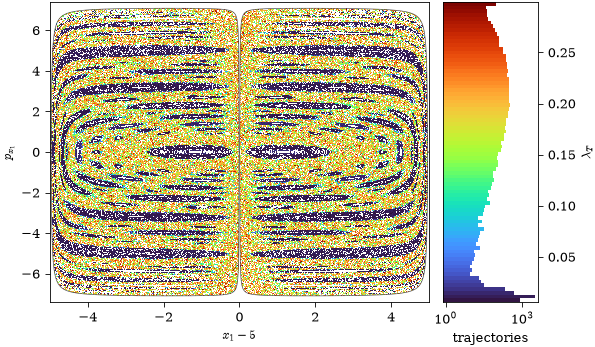

wrote images\fig_lyapunov_section.pdf
Cache hit: D:\2particle-numerics\tmp\lyapunov_orbit_cache\orbits_d774e6360b78ad57.json
cache hit: tmp\lyapunov_orbit_cache\local_islands_v1.npz


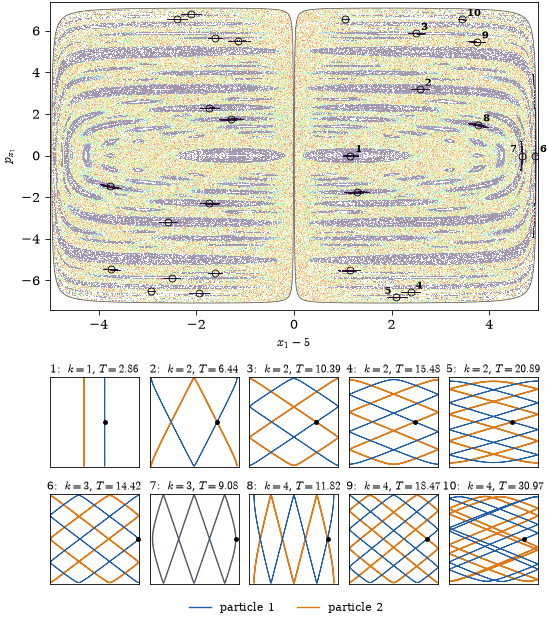

wrote images\fig_islands.pdf


In [7]:
lyap_figs.main()

Fraction of the section covered by islands: the 33 % (area) and 31 %
(return-time weighted) quoted in the text are the `c = 3.2` row.

In [8]:
import runpy
_ = runpy.run_path(str(ROOT / "island_fraction_section.py"), run_name="__main__")

Cache hit: D:\2particle-numerics\tmp\lyapunov_section_cache\section_6e179d7e4a014a19.npz
E = 52.2308, T = 500, 13920 trajectories
returns per trajectory: min 16, median 126
    c     area  weighted
  2.0   0.3297    0.3045
  3.2   0.3343    0.3091
  5.0   0.3404    0.3150


## Appendix B. Two families of periodic orbits

The vertical and the circular orbit, followed in energy. The printed closure
error $|z(T)-z(0)|$ checks that each parsed point is periodic.

Figures `fig_vertical_family.pdf` and `fig_circular_family.pdf`.

E =   11.0752   T =    6.8746   closure error = 7.6e-09   max|lambda| = 1.0000


E =    3.8763   T =   14.8013   closure error = 1.3e-09   max|lambda| = 1.0000


E =    3.3225   T =   17.2035   closure error = 1.1e-09   max|lambda| = 2.5916


E =    2.5473   T =   24.3474   closure error = 1.0e-08   max|lambda| = 1.0000


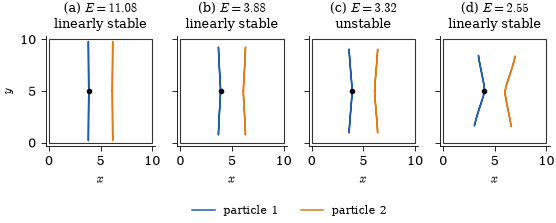

wrote images\fig_vertical_family.pdf


In [9]:
orbit_figs.vertical_figure()

E =    2.0077   T =  101.8202   closure error = 3.1e-08   max|lambda| = 1.0000


E =    2.5096   T =   28.7374   closure error = 6.8e-09   max|lambda| = 1.0000


E =    3.0115   T =   23.8023   closure error = 6.3e-09   max|lambda| = 1.0000


E =    3.5134   T =   20.9497   closure error = 1.7e-09   max|lambda| = 1.0000
E =    4.0153   T =   18.9352   closure error = 1.9e-09   max|lambda| = 1.0000


E =    4.0153   T =   18.9352   closure error = 1.9e-09   max|lambda| = 1.0000
E =   52.2308   T =    4.0776   closure error = 9.4e-10   max|lambda| = 1.0000


E =  202.2308   T =    2.0156   closure error = 1.4e-10   max|lambda| = 1.0000


all circular orbits shown are linearly stable: True


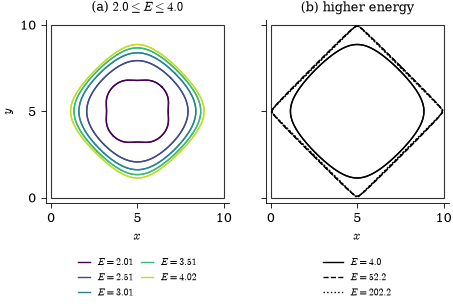

wrote images\fig_circular_family.pdf


In [10]:
orbit_figs.circular_figure()

## Appendix C. Five example trajectories

Figure `fig_cases.pdf`.

case1: E = 1.987653, max dE/E = 1.3e-12


case2: E = 2.007344, max dE/E = 6.0e-08


case3: E = 2.007652, max dE/E = 9.7e-09


case4: E = 402.075156, max dE/E = 1.8e-09


case5: E = 402.002381, max dE/E = 8.9e-09


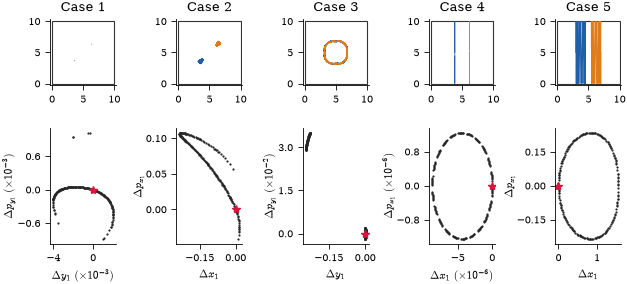

wrote images\fig_cases.pdf


In [11]:
section_figs.cases_figure()